In [1]:

!pip -q install kagglehub

import kagglehub
import os

path = kagglehub.dataset_download(
    "oddrationale/mnist-in-csv"
)

print("Dataset path:", path)
print("Files:", os.listdir(path))


Using Colab cache for faster access to the 'mnist-in-csv' dataset.
Dataset path: /kaggle/input/mnist-in-csv
Files: ['mnist_test.csv', 'mnist_train.csv']


In [ ]:

import pandas as pd

train_df = pd.read_csv(
    os.path.join(path, "mnist_train.csv")
)

test_df = pd.read_csv(
    os.path.join(path, "mnist_test.csv")
)

print("Training data:", train_df.shape)
print("Testing data:", test_df.shape)
print(train_df.head())


Training data: (60000, 785)
Testing data: (10000, 785)
   label  1x1  1x2  1x3  1x4  1x5  1x6  1x7  1x8  1x9  ...  28x19  28x20  \
0      5    0    0    0    0    0    0    0    0    0  ...      0      0   
1      0    0    0    0    0    0    0    0    0    0  ...      0      0   
2      4    0    0    0    0    0    0    0    0    0  ...      0      0   
3      1    0    0    0    0    0    0    0    0    0  ...      0      0   
4      9    0    0    0    0    0    0    0    0    0  ...      0      0   

   28x21  28x22  28x23  28x24  28x25  28x26  28x27  28x28  
0      0      0      0      0      0      0      0      0  
1      0      0      0      0      0      0      0      0  
2      0      0      0      0      0      0      0      0  
3      0      0      0      0      0      0      0      0  
4      0      0      0      0      0      0      0      0  

[5 rows x 785 columns]


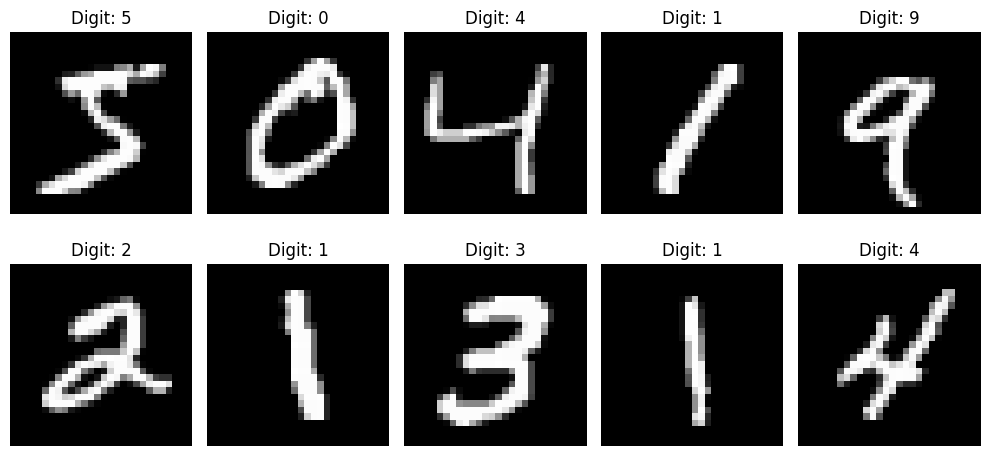

In [ ]:

import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for i, ax in enumerate(axes.flat):
    row = train_df.iloc[i]
    image = row.iloc[1:].to_numpy().reshape(28, 28)

    ax.imshow(image, cmap="gray")
    ax.set_title(f"Digit: {int(row.iloc[0])}")
    ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

from sklearn.model_selection import train_test_split

# Separate sample from Kaggle training data
train_pool, val_df = train_test_split(
    train_df,
    train_size=12000,
    test_size=3000,
    stratify=train_df["label"],
    random_state=42
)

# Independent sample from Kaggle test data
test_sample = test_df.sample(
    n=3000,
    random_state=42
)

X_train = train_pool.iloc[:, 1:].to_numpy(
    dtype="float32"
).reshape(-1, 28, 28, 1) / 255.0

y_train = train_pool["label"].to_numpy()

X_val = val_df.iloc[:, 1:].to_numpy(
    dtype="float32"
).reshape(-1, 28, 28, 1) / 255.0

y_val = val_df["label"].to_numpy()

X_test = test_sample.iloc[:, 1:].to_numpy(
    dtype="float32"
).reshape(-1, 28, 28, 1) / 255.0

y_test = test_sample["label"].to_numpy()

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


Train: (12000, 28, 28, 1)
Validation: (3000, 28, 28, 1)
Test: (3000, 28, 28, 1)


In [ ]:

import tensorflow as tf
from tensorflow.keras import layers, models

tf.keras.utils.set_random_seed(42)

model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
before_loss, before_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("BEFORE TRAINING")
print(f"Test Loss: {before_loss:.4f}")
print(f"Test Accuracy: {before_accuracy * 100:.2f}%")

BEFORE TRAINING
Test Loss: 2.3001
Test Accuracy: 8.20%


In [ ]:

history = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_data=(X_val, y_val),
    verbose=1
)

print("Training completed!")


Epoch 1/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 11s 55ms/step - accuracy: 0.8537 - loss: 0.4956 - val_accuracy: 0.9523 - val_loss: 0.1611
Epoch 2/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 21s 56ms/step - accuracy: 0.9610 - loss: 0.1281 - val_accuracy: 0.9677 - val_loss: 0.1074
Epoch 3/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 9s 48ms/step - accuracy: 0.9730 - loss: 0.0863 - val_accuracy: 0.9740 - val_loss: 0.0890
Epoch 4/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 10s 53ms/step - accuracy: 0.9798 - loss: 0.0627 - val_accuracy: 0.9747 - val_loss: 0.0865
Epoch 5/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 10s 55ms/step - accuracy: 0.9863 - loss: 0.0468 - val_accuracy: 0.9710 - val_loss: 0.1038
Training completed!


In [ ]:
model.save("mnist_trained_original.keras")
print("Original trained model saved!")

Original trained model saved!


In [ ]:

after_loss, after_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("AFTER TRAINING")
print(f"Test Loss: {after_loss:.4f}")
print(f"Test Accuracy: {after_accuracy * 100:.2f}%")


AFTER TRAINING
Test Loss: 0.0966
Test Accuracy: 96.80%


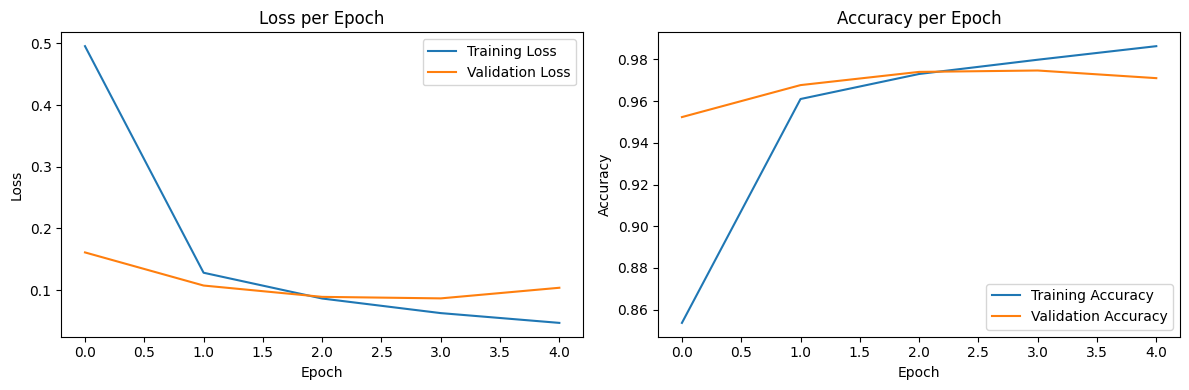

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Loss per Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Accuracy per Epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.savefig("training_curves.png", dpi=150)
plt.show()


In [ ]:

import pandas as pd

comparison = pd.DataFrame({
    "Metric": ["Test Accuracy (%)", "Test Loss"],
    "Before Training": [
        round(before_accuracy * 100, 2),
        round(before_loss, 4)
    ],
    "After Training": [
        round(after_accuracy * 100, 2),
        round(after_loss, 4)
    ]
})

display(comparison)

print("\nConclusion:")
print(
    "Before training, the CNN achieved 8.20% test accuracy. "
    "After five epochs, accuracy increased to 96.80%, "
    "while test loss decreased from 2.3001 to 0.0966. "
    "This improvement shows that the CNN successfully "
    "learned to recognize handwritten digits."
)


,Metric,Before Training,After Training
0,Test Accuracy (%),8.2000,96.8000
1,Test Loss,2.3001,0.0966



Conclusion:
Before training, the CNN achieved 8.20% test accuracy. After five epochs, accuracy increased to 96.80%, while test loss decreased from 2.3001 to 0.0966. This improvement shows that the CNN successfully learned to recognize handwritten digits.
